# Proyecto final — Emisiones de CO₂ per cápita
## Notebook 2: Visualización y análisis exploratorio

**Curso:** Ciencia de Datos — Actividad 4: Proyecto final
**Institución:** Fundación Universitaria Agraria de Colombia (UNIAGRARIA)
**Responsable de este notebook:** José Alejandro Ochoa (GitHub: `Jos38a`)
**Equipo:** Juan Felipe Castañeda Rodríguez · José Alejandro Ochoa · Ricardo José Díaz

---

Este notebook usa los datos limpios del **Notebook 1** (`data/co2_paises_limpio.csv`, `data/co2_mundo.csv` y `data/co2_grupos_ingreso.csv`) para explorar las ideas centrales de la sección **"Per capita CO₂ emissions"** del artículo de Our World in Data:

1. ¿Cómo han evolucionado las emisiones globales, en total y por persona?
2. ¿Qué tan desiguales son las emisiones per cápita entre países y grupos de ingreso?
3. ¿Qué relación hay entre el ingreso de un país y sus emisiones por persona?

Se toma **2024** como año de referencia, porque es el año más reciente con datos consolidados (los de 2025 son una proyección preliminar del Global Carbon Project).

## 1. Preparación

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

paises = pd.read_csv("../data/co2_paises_limpio.csv")
mundo = pd.read_csv("../data/co2_mundo.csv")
grupos = pd.read_csv("../data/co2_grupos_ingreso.csv")

# Estilo común de las gráficas: colores consistentes y ejes discretos
AZUL, NARANJA, VERDE, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85"
TEXTO, TEXTO_2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})
ANIO = 2024
promedio_mundial = mundo.loc[mundo["year"] == ANIO, "co2_per_capita"].item()
print(f"Países: {paises['country'].nunique()} | años {paises['year'].min()}-{paises['year'].max()}")
print(f"Promedio mundial de emisiones per cápita en {ANIO}: {promedio_mundial:.2f} t de CO₂ por persona")

Países: 196 | años 1950-2025
Promedio mundial de emisiones per cápita en 2024: 4.74 t de CO₂ por persona


## 2. Emisiones globales desde la Revolución Industrial

El artículo explica que antes de la Revolución Industrial las emisiones eran muy bajas y que crecieron rápidamente desde mediados del siglo XX. Se grafican en miles de millones de toneladas (Gt).

En 2024 el mundo emitió 38.6 Gt, 6.5 veces lo de 1950.


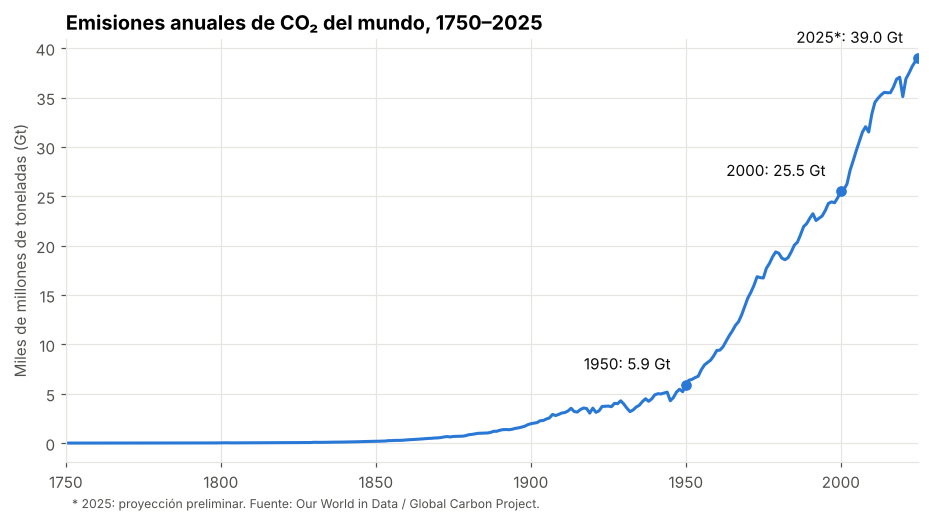

In [2]:
serie = mundo.dropna(subset=["co2"])
fig, ax = plt.subplots()
ax.plot(serie["year"], serie["co2"] / 1000, color=AZUL)
ax.set_title("Emisiones anuales de CO₂ del mundo, 1750–2025")
ax.set_ylabel("Miles de millones de toneladas (Gt)")
ax.set_xlim(1750, 2025)
for anio, texto in [(1950, "1950"), (2000, "2000"), (2025, "2025*")]:
    valor = serie.loc[serie["year"] == anio, "co2"].item() / 1000
    ax.annotate(f"{texto}: {valor:.1f} Gt", (anio, valor), textcoords="offset points",
                xytext=(-10, 10), ha="right", color=TEXTO)
    ax.plot(anio, valor, "o", color=AZUL, markersize=6)
ax.text(1752, -0.08, "* 2025: proyección preliminar. Fuente: Our World in Data / Global Carbon Project.",
        transform=ax.get_xaxis_transform(), color=TEXTO_2, fontsize=8, va="top")
plt.show()

e1950 = serie.loc[serie["year"] == 1950, "co2"].item()
e2024 = serie.loc[serie["year"] == ANIO, "co2"].item()
print(f"En {ANIO} el mundo emitió {e2024/1000:.1f} Gt, {e2024/e1950:.1f} veces lo de 1950.")

**Interpretación.** Hasta mediados del siglo XIX las emisiones eran prácticamente nulas. Empiezan a subir con la industrialización y se aceleran mucho después de 1950: en 2024 el mundo emitió **38,6 Gt de CO₂, 6,5 veces lo de 1950**. La proyección para 2025 (39,0 Gt) indica que las emisiones globales **todavía no han dejado de crecer**, aunque lo hacen más despacio que entre 1950 y 2010. Es la misma tendencia que describe el artículo en su sección sobre las emisiones globales.

## 3. Emisiones por persona en el mundo

Las emisiones totales crecen tanto por el aumento de la población como por el de las emisiones de cada persona. Para separar los dos efectos se grafica el promedio mundial **por persona**.

,t CO₂ por persona,población (miles de millones)
year,,
1950,2.376,2.49
1979,4.434,4.37
2000,4.133,6.17
2011,4.853,7.11
2020,4.450,7.89
2024,4.735,8.16


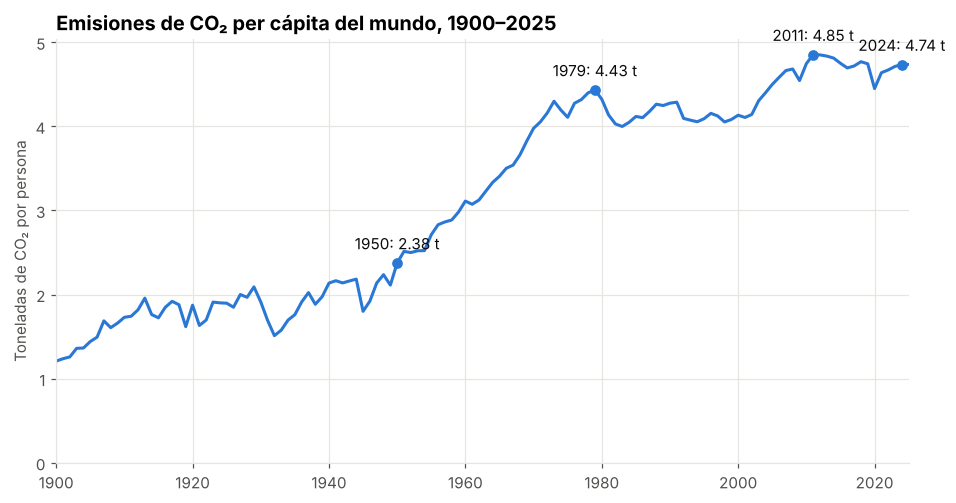

In [3]:
serie_pc = mundo.dropna(subset=["co2_per_capita"])
serie_pc = serie_pc[serie_pc["year"] >= 1900]
fig, ax = plt.subplots()
ax.plot(serie_pc["year"], serie_pc["co2_per_capita"], color=AZUL)
ax.set_title("Emisiones de CO₂ per cápita del mundo, 1900–2025")
ax.set_ylabel("Toneladas de CO₂ por persona")
ax.set_ylim(0, None)
ax.set_xlim(1900, 2025)
for anio in [1950, 1979, 2011, ANIO]:
    v = serie_pc.loc[serie_pc["year"] == anio, "co2_per_capita"].item()
    ax.plot(anio, v, "o", color=AZUL, markersize=6)
    ax.annotate(f"{anio}: {v:.2f} t", (anio, v), textcoords="offset points", xytext=(0, 9),
                ha="center", color=TEXTO)
plt.show()

tabla = serie_pc.set_index("year").loc[[1950, 1979, 2000, 2011, 2020, ANIO], ["co2_per_capita", "population"]]
tabla["population"] = (tabla["population"] / 1e9).round(2)
display(tabla.rename(columns={"co2_per_capita": "t CO₂ por persona", "population": "población (miles de millones)"}))

**Interpretación.** La historia por persona es distinta a la del total. Las emisiones per cápita se duplicaron entre 1950 (2,38 t) y 1979 (4,43 t), y desde entonces se han movido en una franja estrecha, entre 4 y 4,9 toneladas. El máximo fue en 2011 (4,85 t) y en 2024 el valor fue de 4,74 t.

En el mismo periodo la población mundial pasó de 4 370 millones (1979) a 8 160 millones (2024). Es decir: **desde finales de los años setenta, el aumento de las emisiones totales se explica sobre todo por el crecimiento de la población**, no porque cada persona emita más. Esto justifica analizar los datos per cápita, como propone la sección elegida del artículo.

## 4. Los países con mayores emisiones per cápita

El artículo señala que los mayores emisores por persona son productores de petróleo de Oriente Medio, y que Estados Unidos, Australia y Canadá emiten alrededor de tres veces el promedio mundial. Se ordenan los 15 países con más emisiones per cápita en 2024 y se marca el promedio mundial como referencia.

United States: 14.2 t por persona = 3.0 veces el promedio mundial
Australia: 14.4 t por persona = 3.0 veces el promedio mundial
Canada: 13.6 t por persona = 2.9 veces el promedio mundial


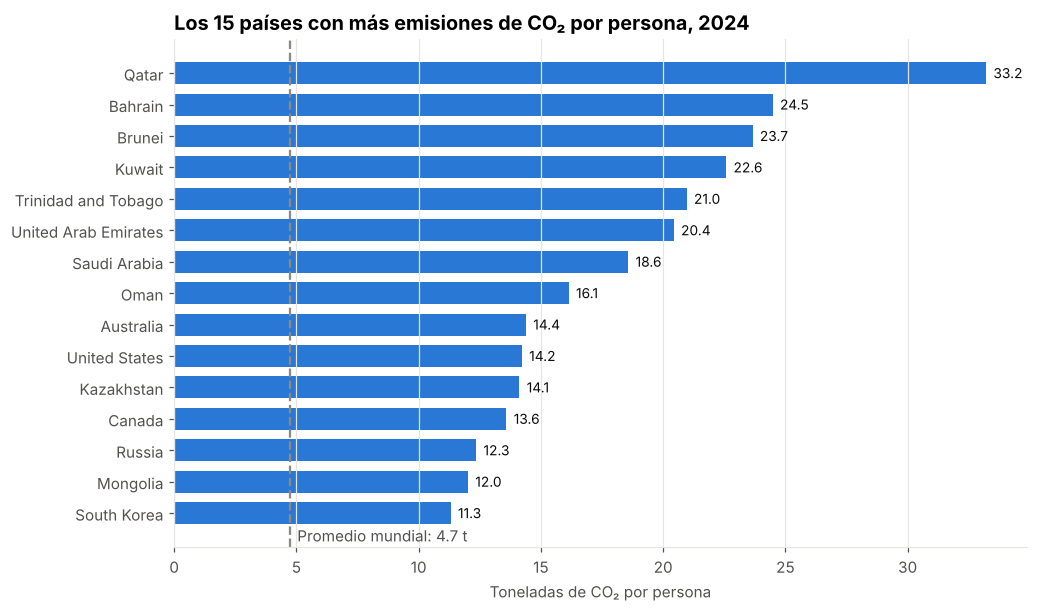

In [4]:
top = (paises[paises["year"] == ANIO]
       .nlargest(15, "co2_per_capita")
       .sort_values("co2_per_capita"))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["country"], top["co2_per_capita"], color=AZUL, height=0.7)
ax.axvline(promedio_mundial, color=GRIS, linestyle="--", linewidth=1.5)
ax.text(promedio_mundial + 0.3, -0.9, f"Promedio mundial: {promedio_mundial:.1f} t", color=TEXTO_2)
for y, v in enumerate(top["co2_per_capita"]):
    ax.text(v + 0.3, y, f"{v:.1f}", va="center", color=TEXTO, fontsize=9)
ax.set_title(f"Los 15 países con más emisiones de CO₂ por persona, {ANIO}")
ax.set_xlabel("Toneladas de CO₂ por persona")
ax.grid(axis="y", visible=False)
plt.show()

for pais in ["United States", "Australia", "Canada"]:
    v = paises.loc[(paises["country"] == pais) & (paises["year"] == ANIO), "co2_per_capita"].item()
    print(f"{pais}: {v:.1f} t por persona = {v / promedio_mundial:.1f} veces el promedio mundial")

**Interpretación.** Los ocho primeros lugares son productores de petróleo y gas: Qatar encabeza la lista con **33,2 t por persona, unas 7 veces el promedio mundial**, seguido de Baréin, Brunéi, Kuwait, Trinidad y Tobago, Emiratos, Arabia Saudita y Omán. Esto coincide con lo que dice el artículo.

El dato del artículo sobre Estados Unidos, Australia y Canadá se confirma con exactitud: los tres emiten **2,9 a 3,0 veces el promedio mundial**. Les siguen Kazajistán, Rusia y Mongolia, economías que dependen mucho del carbón y del gas, y Corea del Sur, con una industria pesada intensiva en energía.

## 5. Desigualdad entre grupos de ingreso

Los datos incluyen los cuatro grupos de ingreso del Banco Mundial. Esta gráfica compara la evolución de las emisiones por persona en cada grupo.

,t por persona,veces el ingreso bajo
country,,
Ingreso alto,9.73,34.8
Ingreso medio-alto,6.12,21.9
Ingreso medio-bajo,1.58,5.6
Ingreso bajo,0.28,1.0


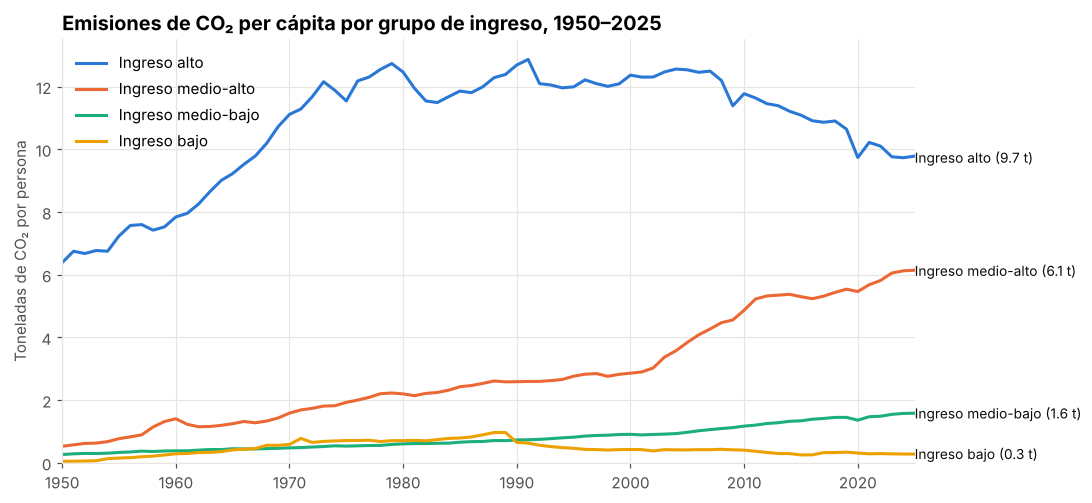

In [5]:
ETIQUETAS = {"High-income countries": "Ingreso alto",
             "Upper-middle-income countries": "Ingreso medio-alto",
             "Lower-middle-income countries": "Ingreso medio-bajo",
             "Low-income countries": "Ingreso bajo"}
COLORES = {"High-income countries": AZUL, "Upper-middle-income countries": NARANJA,
           "Lower-middle-income countries": VERDE, "Low-income countries": AMARILLO}
g = grupos[grupos["year"] >= 1950].dropna(subset=["co2_per_capita"])

fig, ax = plt.subplots()
for grupo, color in COLORES.items():
    d = g[g["country"] == grupo]
    ax.plot(d["year"], d["co2_per_capita"], color=color, label=ETIQUETAS[grupo])
    ultimo = d[d["year"] == ANIO]["co2_per_capita"].item()
    ax.text(ANIO + 1, ultimo, f"{ETIQUETAS[grupo]} ({ultimo:.1f} t)", va="center", color=TEXTO, fontsize=9)
ax.set_title("Emisiones de CO₂ per cápita por grupo de ingreso, 1950–2025")
ax.set_ylabel("Toneladas de CO₂ por persona")
ax.set_xlim(1950, 2025)
ax.set_ylim(0, None)
ax.legend(loc="upper left")
plt.show()

tabla = (g[g["year"] == ANIO].set_index("country")["co2_per_capita"]
         .rename(index=ETIQUETAS).loc[list(ETIQUETAS.values())].round(2).to_frame("t por persona"))
tabla["veces el ingreso bajo"] = (tabla["t por persona"] / tabla.loc["Ingreso bajo", "t por persona"]).round(1)
display(tabla)

**Interpretación.** La desigualdad es enorme: una persona en un país de **ingreso alto emitió 9,7 t en 2024, unas 35 veces más que una persona en un país de ingreso bajo (0,28 t)**. Las tendencias también son diferentes:

- **Ingreso alto:** se mantuvo cerca de 12–13 t desde finales de los años setenta hasta mediados de los 2000, y desde entonces baja. En 2024 está en 9,7 t, el nivel de finales de los años sesenta.
- **Ingreso medio-alto:** es el grupo que más creció desde el año 2000 (de unas 3 t a 6,1 t), impulsado sobre todo por China.
- **Ingreso medio-bajo y bajo:** han crecido muy poco y siguen por debajo de 2 t y de 0,5 t por persona.

Que el orden de las cuatro líneas siga exactamente el orden del ingreso es una primera evidencia de la relación ingreso–emisiones que se modela en el notebook 3.

## 6. Distribución de las emisiones per cápita entre países

Las gráficas anteriores muestran extremos y promedios. Un histograma muestra **cómo se reparten todos los países**. Como los valores van de 0,03 a más de 30 toneladas, el eje horizontal se dibuja en escala logarítmica: cada marca representa diez veces la anterior.

Mínimo: 0.04 t (Democratic Republic of Congo) | Máximo: 33.21 t (Qatar)
Razón máximo / mínimo: 791 veces
Países por debajo de 1 t: 55 | por encima de 10 t: 17


,country,co2_per_capita
0,Democratic Republic of Congo,0.042
1,Burundi,0.053
2,Somalia,0.068
3,Central African Republic,0.084
4,Malawi,0.084


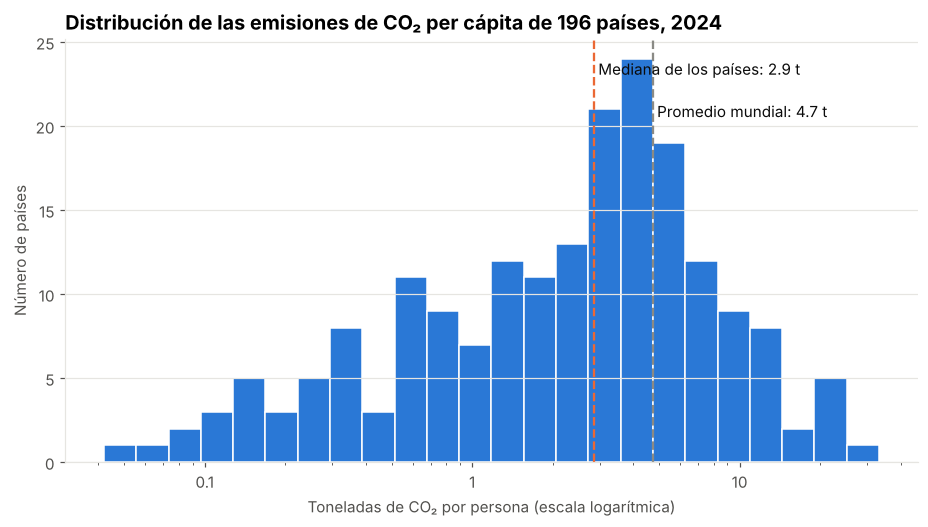

In [6]:
d = paises[paises["year"] == ANIO]["co2_per_capita"]
bins = np.logspace(np.log10(d.min()), np.log10(d.max()), 25)
fig, ax = plt.subplots()
ax.hist(d, bins=bins, color=AZUL, edgecolor="white", linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
ax.axvline(d.median(), color=NARANJA, linestyle="--", linewidth=1.5)
ax.axvline(promedio_mundial, color=GRIS, linestyle="--", linewidth=1.5)
ax.text(d.median(), ax.get_ylim()[1] * 0.95, f" Mediana de los países: {d.median():.1f} t", color=TEXTO, va="top")
ax.text(promedio_mundial, ax.get_ylim()[1] * 0.85, f" Promedio mundial: {promedio_mundial:.1f} t", color=TEXTO, va="top")
ax.set_title(f"Distribución de las emisiones de CO₂ per cápita de {len(d)} países, {ANIO}")
ax.set_xlabel("Toneladas de CO₂ por persona (escala logarítmica)")
ax.set_ylabel("Número de países")
ax.grid(axis="x", visible=False)
plt.show()

print(f"Mínimo: {d.min():.2f} t ({paises.loc[d.idxmin(), 'country']}) | Máximo: {d.max():.2f} t ({paises.loc[d.idxmax(), 'country']})")
print(f"Razón máximo / mínimo: {d.max() / d.min():.0f} veces")
print(f"Países por debajo de 1 t: {(d < 1).sum()} | por encima de 10 t: {(d > 10).sum()}")
bajos = paises[(paises["year"] == ANIO)].nsmallest(5, "co2_per_capita")[["country", "co2_per_capita"]]
display(bajos.round(3).reset_index(drop=True))

**Interpretación.** El histograma muestra lo que el artículo llama *desigualdades muy grandes*:

- Entre el país que más emite (Qatar, 33,2 t) y el que menos emite (República Democrática del Congo, 0,04 t) hay una diferencia de **casi 800 veces**.
- **55 países emiten menos de 1 tonelada por persona** y 17 emiten más de 10.
- La **mediana de los países (2,9 t) es menor que el promedio mundial (4,7 t)**. El promedio mundial pondera por población y lo jalan hacia arriba países muy poblados con emisiones altas, como China y Estados Unidos. El "país típico" emite menos que el promedio mundial.

El artículo menciona que países como Chad, Níger y la República Centroafricana emiten alrededor de 0,1 t por persona. Los datos de 2024 lo confirman: la República Centroafricana registra 0,084 t, y los cinco países con menos emisiones están entre 0,04 y 0,08 t.

## 7. Colombia frente a otros países

Para ubicar a Colombia se compara su trayectoria con la del promedio mundial, Estados Unidos y China, el mayor emisor total del mundo.

year,1990,2005,2024
country,,,
China,2.16,4.51,8.74
Colombia,1.73,1.49,2.01
United States,20.25,20.71,14.22
Mundo,4.28,4.50,4.74


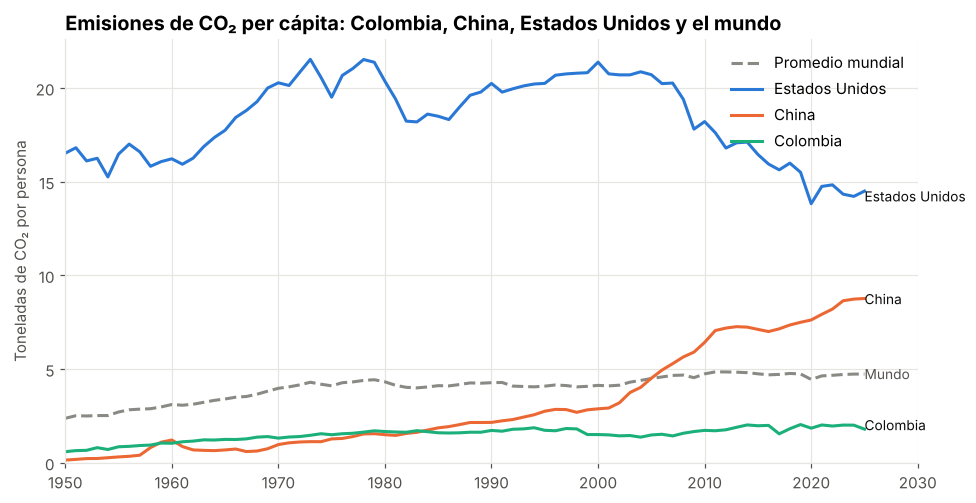

In [7]:
SERIES = [("United States", "Estados Unidos", AZUL), ("China", "China", NARANJA),
          ("Colombia", "Colombia", VERDE)]
fig, ax = plt.subplots()
m = mundo[(mundo["year"] >= 1950)].dropna(subset=["co2_per_capita"])
ax.plot(m["year"], m["co2_per_capita"], color=GRIS, linestyle="--", label="Promedio mundial")
ax.text(ANIO + 1, m[m["year"] == ANIO]["co2_per_capita"].item(), "Mundo", va="center", color=TEXTO_2, fontsize=9)
for pais, nombre, color in SERIES:
    d = paises[paises["country"] == pais]
    ax.plot(d["year"], d["co2_per_capita"], color=color, label=nombre)
    ax.text(ANIO + 1, d[d["year"] == ANIO]["co2_per_capita"].item(), nombre, va="center", color=TEXTO, fontsize=9)
ax.set_title("Emisiones de CO₂ per cápita: Colombia, China, Estados Unidos y el mundo")
ax.set_ylabel("Toneladas de CO₂ por persona")
ax.set_xlim(1950, 2030)
ax.set_ylim(0, None)
ax.legend(loc="upper right")
plt.show()

comp = (paises[paises["country"].isin(["Colombia", "China", "United States"]) & paises["year"].isin([1990, 2005, ANIO])]
        .pivot(index="country", columns="year", values="co2_per_capita").round(2))
comp.loc["Mundo"] = mundo.set_index("year").loc[[1990, 2005, ANIO], "co2_per_capita"].round(2).values
display(comp)

**Interpretación.**

- **Colombia** emitió **2,0 t por persona en 2024, menos de la mitad del promedio mundial (4,7 t)** y unas 7 veces menos que Estados Unidos. Su valor casi no ha cambiado desde 1990 (1,7 t). Esto es coherente con una matriz eléctrica basada principalmente en hidroelectricidad, aunque en el país las emisiones por cambio en el uso del suelo (deforestación), que este indicador no incluye, son importantes.
- **China** pasó de 2,2 t en 1990 a **8,7 t en 2024**: superó el promedio mundial hacia 2005 y hoy está cerca del nivel de los países de ingreso alto.
- **Estados Unidos** bajó de 20,7 t en 2005 a **14,2 t en 2024**, una caída de casi un tercio, mientras su economía siguió creciendo. Aun así, sigue emitiendo 3 veces el promedio mundial.

Las trayectorias muestran que las emisiones per cápita no dependen solo del ingreso: las decisiones de energía y tecnología también las mueven, como señala el artículo.

## 8. Ingreso y emisiones por persona

Esta es la relación central de la sección del artículo: *"existe una relación fuerte entre el ingreso y las emisiones per cápita"*. Se usa **2022**, el último año con datos de PIB. Ambos ejes van en escala logarítmica, por la misma razón que el histograma.

Países con PIB y emisiones en 2022: 163
Correlación de Pearson en escala original:    r = 0.761
Correlación de Pearson en escala logarítmica: r = 0.911


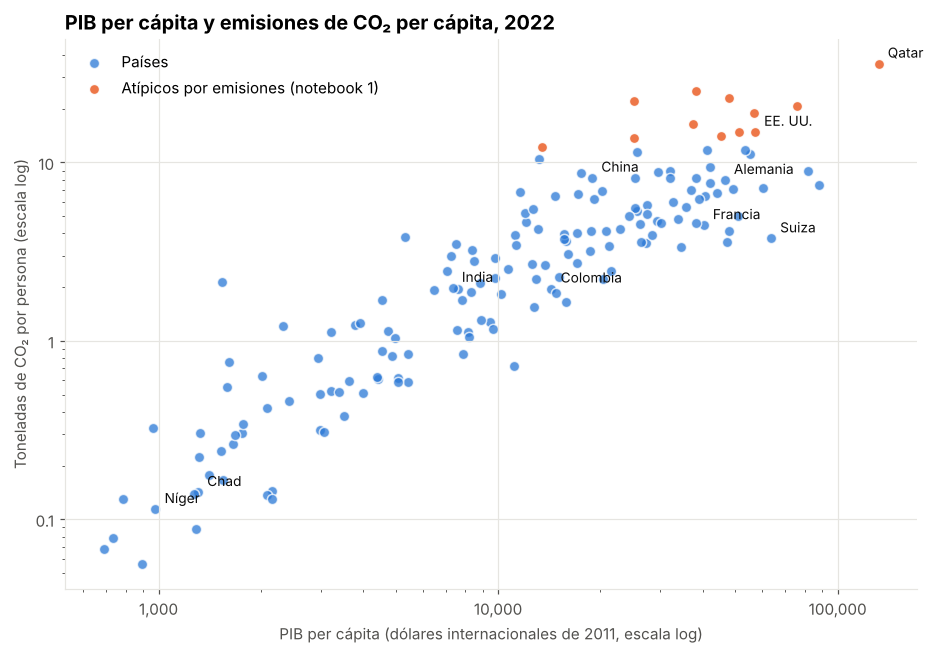

In [8]:
d = paises[(paises["year"] == 2022)].dropna(subset=["gdp_per_capita", "co2_per_capita"])
fig, ax = plt.subplots(figsize=(10, 6.5))
normal = d[~d["atipico_co2_pc"]]
atip = d[d["atipico_co2_pc"]]
ax.scatter(normal["gdp_per_capita"], normal["co2_per_capita"], s=45, color=AZUL, alpha=0.75,
           edgecolor="white", linewidth=1, label="Países")
ax.scatter(atip["gdp_per_capita"], atip["co2_per_capita"], s=45, color=NARANJA, alpha=0.9,
           edgecolor="white", linewidth=1, label="Atípicos por emisiones (notebook 1)")
ax.set_xscale("log"); ax.set_yscale("log")
for eje in (ax.xaxis, ax.yaxis):
    eje.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}" if x >= 1 else f"{x:g}"))
for pais, nombre in [("Qatar", "Qatar"), ("United States", "EE. UU."), ("France", "Francia"),
                     ("Germany", "Alemania"), ("China", "China"), ("Colombia", "Colombia"),
                     ("Chad", "Chad"), ("Niger", "Níger"), ("India", "India"), ("Switzerland", "Suiza")]:
    fila = d[d["country"] == pais]
    if len(fila):
        ax.annotate(nombre, (fila["gdp_per_capita"].item(), fila["co2_per_capita"].item()),
                    textcoords="offset points", xytext=(6, 4), color=TEXTO, fontsize=9)
ax.set_title("PIB per cápita y emisiones de CO₂ per cápita, 2022")
ax.set_xlabel("PIB per cápita (dólares internacionales de 2011, escala log)")
ax.set_ylabel("Toneladas de CO₂ por persona (escala log)")
ax.legend(loc="upper left")
plt.show()

r_lin = d["gdp_per_capita"].corr(d["co2_per_capita"])
r_log = d["log_gdp_pc"].corr(d["log_co2_pc"])
print(f"Países con PIB y emisiones en 2022: {len(d)}")
print(f"Correlación de Pearson en escala original:    r = {r_lin:.3f}")
print(f"Correlación de Pearson en escala logarítmica: r = {r_log:.3f}")

**Interpretación.** La nube de puntos sube de izquierda a derecha: **a mayor PIB per cápita, mayores emisiones por persona**. En escala logarítmica la relación es casi una línea recta, con una correlación de **r = 0,91**, mucho más alta que en la escala original (r = 0,76). Esto indica que la relación es de tipo **proporcional**: cuando el ingreso se multiplica, las emisiones también se multiplican. Por eso el modelo del notebook 3 se plantea en logaritmos.

También se ve lo que el artículo advierte: a un mismo nivel de ingreso hay países que emiten muy distinto. **Francia y Suiza** quedan por debajo de la nube, gracias a su electricidad nuclear e hidroeléctrica, mientras que **Estados Unidos y Alemania** quedan por encima. Los productores de petróleo (puntos naranjas) están por encima de lo que les correspondería por su ingreso.

## 9. Matriz de correlación

Para terminar la exploración se miden las correlaciones (en escala logarítmica) entre las emisiones per cápita, el ingreso, el consumo de energía por persona y la población, en 2022.

,CO₂ per cápita,PIB per cápita,Energía per cápita,Población
CO₂ per cápita,1.000,0.911,0.976,-0.123
PIB per cápita,0.911,1.000,0.942,-0.106
Energía per cápita,0.976,0.942,1.000,-0.128
Población,-0.123,-0.106,-0.128,1.000


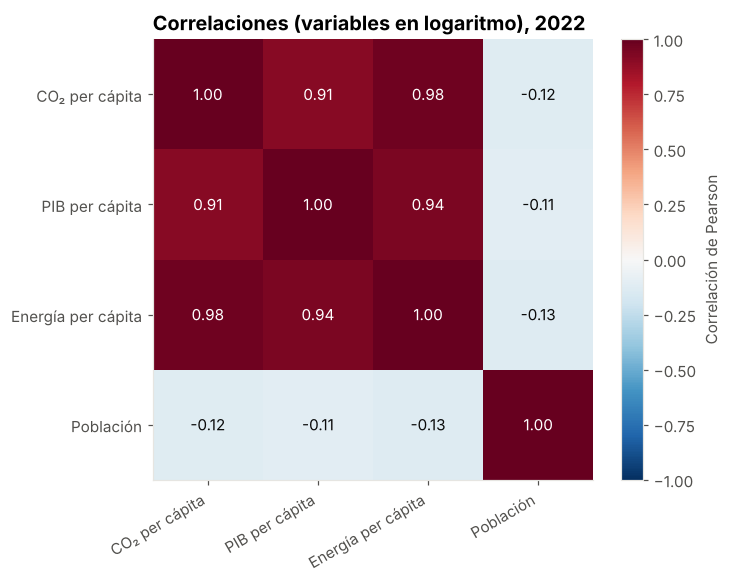

In [9]:
d = paises[paises["year"] == 2022].copy()
d["log_energia_pc"] = np.log10(d["energy_per_capita"].where(d["energy_per_capita"] > 0))
d["log_poblacion"] = np.log10(d["population"])
vars_ = {"log_co2_pc": "CO₂ per cápita", "log_gdp_pc": "PIB per cápita",
         "log_energia_pc": "Energía per cápita", "log_poblacion": "Población"}
corr = d[list(vars_)].corr().rename(index=vars_, columns=vars_)

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(vars_)), corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(vars_)), corr.index)
ax.grid(False)
for i in range(len(vars_)):
    for j in range(len(vars_)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.6 else TEXTO)
fig.colorbar(im, ax=ax, fraction=0.046, label="Correlación de Pearson")
ax.set_title("Correlaciones (variables en logaritmo), 2022")
plt.show()
display(corr.round(3))

**Interpretación.**

- El **consumo de energía per cápita** es la variable más correlacionada con las emisiones (r = 0,98), y a su vez está muy correlacionado con el ingreso (r = 0,94). El mecanismo es: **más ingreso → más consumo de energía → más CO₂**, mientras la energía venga principalmente de combustibles fósiles.
- La **población** casi no se relaciona con las emisiones per cápita (r = −0,12): ser un país grande no significa que cada habitante emita más.
- Para la regresión se usa el **PIB per cápita** como variable explicativa, porque es la que plantea el artículo y porque la energía es más bien una consecuencia del ingreso que una causa independiente. Usar las dos al mismo tiempo generaría multicolinealidad (r = 0,94 entre ellas).

## Conclusiones del análisis exploratorio

1. Las emisiones globales siguen creciendo (38,6 Gt en 2024), pero las emisiones **por persona** están estancadas en torno a 4,7 t desde hace cuatro décadas: el crecimiento reciente del total viene sobre todo del aumento de la población.
2. La desigualdad es enorme: los países de ingreso alto emiten unas **35 veces más por persona** que los de ingreso bajo, y entre el país que más emite y el que menos hay una diferencia de casi 800 veces.
3. Se confirman las afirmaciones del artículo: los productores de petróleo encabezan el ranking; Estados Unidos, Australia y Canadá emiten unas 3 veces el promedio mundial; y los países más pobres emiten alrededor de 0,1 t por persona o menos.
4. Colombia emite 2,0 t por persona, menos de la mitad del promedio mundial, y su nivel casi no ha cambiado desde 1990.
5. El PIB per cápita y las emisiones per cápita tienen una relación fuerte y **lineal en escala logarítmica** (r = 0,91).

**Hipótesis para el modelo (notebook 3):** el logaritmo de las emisiones per cápita se puede explicar con una regresión lineal sobre el logaritmo del PIB per cápita. Los residuos del modelo deberían señalar a los países cuya matriz energética los hace emitir más o menos de lo esperado para su nivel de ingreso.